# Trajectory analysis of the replayable hierarchy run (run 11)

Run 11 trains the run-10 design (80-30-40; balanced output, path-sign-aware cues, equalised cue blocks,
balanced +-10-quanta third-layer paths; cues frozen) on 1M training points with batch 10 000, so one
epoch is 100 steps; 10 000 epochs (1M steps), lr 0.01 annealed by cosine to 0.0005, momentum 0.9.
Weights **and momentum buffers** are stored every 10 epochs (1000 steps), so the training between any
two adjacent checkpoints can be replayed exactly, step by step, with the mini-batch gradient, the update
and (optionally) the population gradient of every step. Files: `results/designed_init/hierarchy_replayable/replay/`
(`weights.npz`, `momentum.npz`, `meta.pkl`; loader `load_designed_run`), produced by
`results/designed_init/run_hierarchy_replayable.py`.

Tools: `replay_interval_from_snapshot` (exact replay between checkpoints, per-step records),
`population_gradient_at_snapshot`, `first_layer_gradient_series` / `plot_first_layer_gradient_series`
(components along ODT nodes and the off-span norm), `first_layer_alignment_series` /
`plot_first_layer_alignment_series`, `probe_gradient_stats`, `hierarchy_run_summary`.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import HIERARCHY_TARGETS, NODE_LEVEL, hierarchy_run_summary, probe_node_outcomes, plot_probe_target_cosines, probe_gradient_stats
from layer_lenses.relu_analysis import (load_designed_run, regenerate_seed_result_data, replay_interval_from_snapshot, population_gradient_at_snapshot,
                                         first_layer_gradient_series, plot_first_layer_gradient_series, first_layer_alignment_series, plot_first_layer_alignment_series,
                                         snapshot_state_dict, first_layer_odt_alignment, plot_layered_relu_graph)

RUN_DIR = Path("../results/designed_init/hierarchy_replayable")
sr = load_designed_run(RUN_DIR / "replay")
tree = sr["tree"]; cfg = sr["train_config"]; out = sr["out"]
data = regenerate_seed_result_data(sr)                      # 1M training points + 200k test points, from their seeds (~3 s)
epochs = np.array(sorted(out["checkpoint_snapshots"])); steps_per_epoch = data["x_train"].shape[0] // cfg.batch_size
W = {k: np.stack([out["checkpoint_snapshots"][e][k].numpy() for e in epochs]) for k in out["checkpoint_snapshots"][epochs[0]]}
run = {"tag": sr["tag"], "epochs": epochs, "W": W, "losses": np.array(out["epoch_losses"]), "lr": np.array(out["lr_history"])}
print(f"{sr['tag']}: {len(epochs)} snapshots every {epochs[1]} epochs ({epochs[1] * steps_per_epoch} steps); {cfg.epochs} epochs x {steps_per_epoch} steps; design flipped units {sr['design']['flipped_units']}")


linear_frozen_kaiming_cosine_replayable_80_seed0: 1001 snapshots every 10 epochs (1000 steps); 10000 epochs x 100 steps; design flipped units [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29]


## 1. Overview: loss, probe cosines to their targets, node coverage

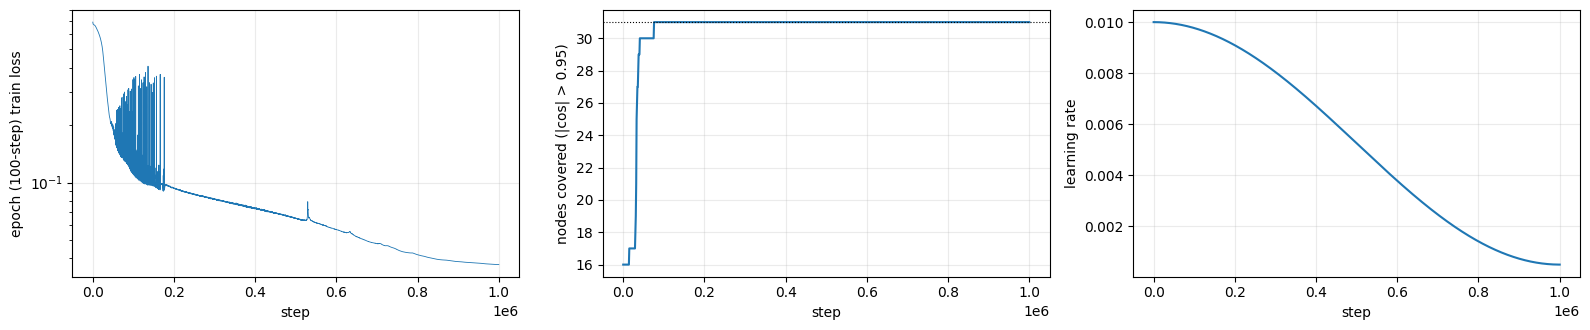

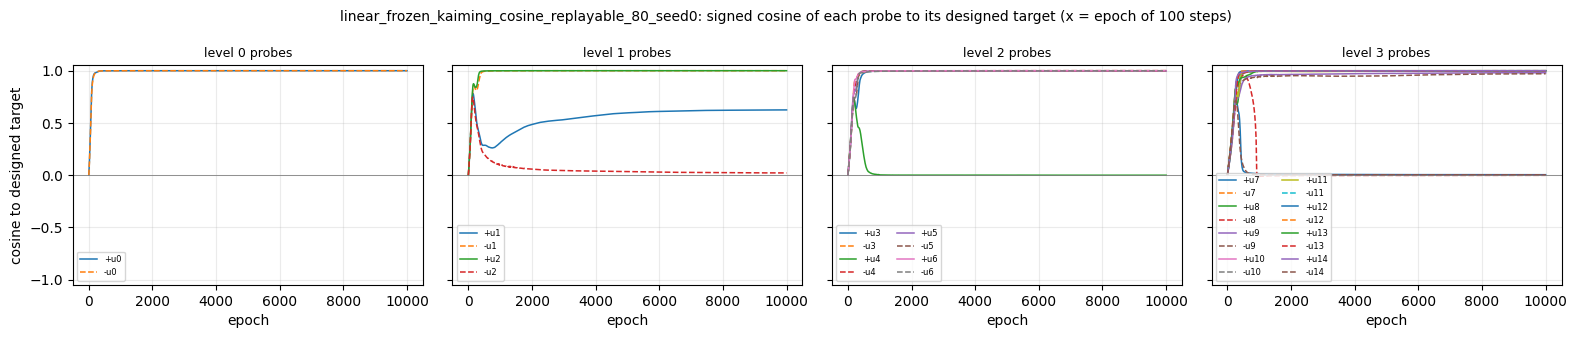

{'aligned_rows': 72, 'rows': 80, 'nodes_covered': 31, 'own_probe_nodes': 15, 'intended_pole': 15, 'opposite_pole_only': 0, 'both_poles': [0, 3, 5, 6, 9, 10, 11, 12, 13], 'missed_by_own_probes': []}


,node,level,probe_plus,probe_minus,own,intended,opposite,others
0,0,0,+u0(1.00),-u0(1.00),2,True,False,1
1,1,1,-u0(0.77),-u1(1.00),1,True,False,1
2,2,1,+u2(1.00),+u0(1.00),1,True,False,1
3,3,2,+u3(1.00),-u3(1.00),2,True,False,0
4,4,2,+u1(1.00),-u4(1.00),1,True,False,0
5,5,2,+u5(1.00),-u5(1.00),2,True,False,0
6,6,2,+u6(1.00),-u6(1.00),2,True,False,0
7,7,3,+u16(1.00),-u7(1.00),1,True,False,1
8,8,3,+u8(1.00),+u18(1.00),1,True,False,1
9,9,3,+u9(0.98),-u9(0.97),2,True,False,0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
axes[0].plot(np.arange(1, len(run["losses"]) + 1) * steps_per_epoch, run["losses"], lw=0.6); axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("epoch (100-step) train loss")
cov = [hierarchy_run_summary(W["hidden_layers.0.weight"][i], tree)["nodes_covered"] for i in range(len(epochs))]
axes[1].plot(epochs * steps_per_epoch, cov); axes[1].axhline(31, color="k", ls=":", lw=0.8); axes[1].set_xlabel("step"); axes[1].set_ylabel("nodes covered (|cos| > 0.95)")
axes[2].plot(np.arange(1, len(run["lr"]) + 1) * steps_per_epoch, run["lr"]); axes[2].set_xlabel("step"); axes[2].set_ylabel("learning rate")
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()
plot_probe_target_cosines(W["hidden_layers.0.weight"], epochs, tree, title=f"{sr['tag']}: signed cosine of each probe to its designed target (x = epoch of 100 steps)"); plt.show()
s_end = hierarchy_run_summary(W["hidden_layers.0.weight"][-1], tree); print({k: v for k, v in s_end.items() if k != "missing_nodes"})
display(probe_node_outcomes(W["hidden_layers.0.weight"][-1], tree))


## 2. Exact replay of one checkpoint interval

`replay_interval_from_snapshot` restarts from the stored weights and momentum at `EPOCH_START`, replays the
1000 steps to the next checkpoint with the stored learning rates and the fixed batch order, and checks that it
lands exactly on the next snapshot. Per step it records the batch loss, the mini-batch gradient and the update of
the chosen first-layer rows, and the population gradient on those rows over the first `FULL_SUBSAMPLE` training
points (the whole 1M set if None; 200k costs ~20 ms per step, 1M ~100 ms).


In [25]:
EPOCH_START = 0          # any stored snapshot epoch except the last (multiples of 10)
ROWS = [0, 1, 2, 3, 4, 5]    # first-layer rows to record (the u_0, u_1, u_2 probe pairs)
FULL_SUBSAMPLE = 1_000_000     # points for the per-step population gradient; None = all 1M

rep = replay_interval_from_snapshot(sr, EPOCH_START, data=data, device="cuda", record_full_data_gradient=True, full_data_subsample=FULL_SUBSAMPLE, record_params=True, neuron_rows=ROWS)
print(f"replayed epochs {rep['epoch_start']}..{rep['epoch_end']} = {rep['num_steps']} steps; exact to the next snapshot: max |param diff| {rep['verification']['max_abs_param_diff_overall']:.2e}, max |momentum diff| {rep['verification']['max_abs_momentum_diff']:.2e}")


replayed epochs 0..10 = 1000 steps; exact to the next snapshot: max |param diff| 0.00e+00, max |momentum diff| 0.00e+00


In [26]:
print(rep.keys())
print(rep["params_rows"].shape)

dict_keys(['epoch_start', 'epoch_end', 'rows', 'num_steps', 'verification', 'params_after', 'step', 'epoch', 'lr', 'batch_loss', 'grad_rows', 'update_rows', 'full_grad_rows', 'full_data_subsample', 'params_rows'])
(1000, 6, 100)


## 2b. The recorded rows step by step within the interval

`rep["params_rows"]` holds the recorded first-layer rows before every step of the replayed interval. For each row:
cosine to the chosen ODT nodes and the row norm (left panels, from `first_layer_alignment_series`), and the size
of each step's movement, split into the part along the row (norm change) and the part perpendicular to it
(rotation), together with the mini-batch gradient norm (right panels). Set `NODE_IDS_P = None` to use each row's
designed node and the node it is closest to at the end of the interval.


In [ ]:
# params_rows within the interval: cosines to ODT nodes, row norms, and per-step movement of the recorded rows
NODE_IDS_P = None            # list of ODT nodes, or None for designed + closest-at-end nodes of the recorded rows
ROWS_P = ROWS                # subset of the rows recorded in the replay cell

P = rep["params_rows"]; n_steps, _, dim = P.shape; n_rows = W["hidden_layers.0.weight"].shape[1]
Pfull = np.zeros((n_steps, n_rows, dim))
for j, r in enumerate(rep["rows"]):
    Pfull[:, r] = P[:, j]
if NODE_IDS_P is None:
    C_end = (Pfull[-1] / np.maximum(np.linalg.norm(Pfull[-1], axis=1, keepdims=True), 1e-12)) @ tree.w_list.T
    NODE_IDS_P = sorted({HIERARCHY_TARGETS[r][0] for r in ROWS_P if r < 30} | {int(np.abs(C_end[r]).argmax()) for r in ROWS_P})
aser = first_layer_alignment_series(Pfull, rep["step"], tree, neuron_ids=ROWS_P, node_ids=NODE_IDS_P)
fig, axes = plot_first_layer_alignment_series(aser, title=f"rows {ROWS_P} vs ODT nodes {NODE_IDS_P}, steps of the replayed interval (from epoch {EPOCH_START})", show_fan_out=False)
axes[-1].set_xlabel(f"step within the interval"); plt.show()

fig, axes = plt.subplots(len(ROWS_P), 1, figsize=(9, 2.4 * len(ROWS_P)), sharex=True, squeeze=False); axes = axes[:, 0]
for ax, r in zip(axes, ROWS_P):
    j = rep["rows"].index(r); w = P[:, j]; what = w / np.maximum(np.linalg.norm(w, axis=1, keepdims=True), 1e-12); dw = rep["update_rows"][:, j]
    along = np.einsum("td,td->t", dw, what); perp = np.linalg.norm(dw - along[:, None] * what, axis=1)
    ax.plot(rep["step"], np.abs(along), lw=0.9, label="|step along the row| (norm change)"); ax.plot(rep["step"], perp, lw=0.9, label="|step perpendicular to the row| (rotation)")
    ax.plot(rep["step"], np.linalg.norm(rep["grad_rows"][:, j], axis=1), lw=0.7, ls=":", color="gray", label="mini-batch gradient norm")
    ax.set_yscale("log"); ax.set_ylabel("per-step size"); ax.set_title(f"row {r} ({'+' if HIERARCHY_TARGETS[r][1] > 0 else '-'}u{HIERARCHY_TARGETS[r][0]})" if r < 30 else f"row {r}", fontsize=9); ax.grid(alpha=0.25); ax.legend(fontsize=6, ncol=3)
axes[-1].set_xlabel("step within the interval"); fig.tight_layout(); plt.show()
aser = aser.rename(columns={"epoch": "step"})          # the series tool names its time column "epoch"; here it is the step
display(aser[aser.step.isin([0, 250, 500, 750, n_steps - 1])].round(4).set_index(["neuron", "step"]))


## 3. Per-step population gradient on chosen rows vs step

Components of the per-step push (-grad) along chosen ODT nodes and the off-span norm, for the rows recorded above.
The step-level view shows what the 10-epoch snapshots cannot: whether the push is a steady drift or an oscillation
whose phase the snapshots happen to sample.


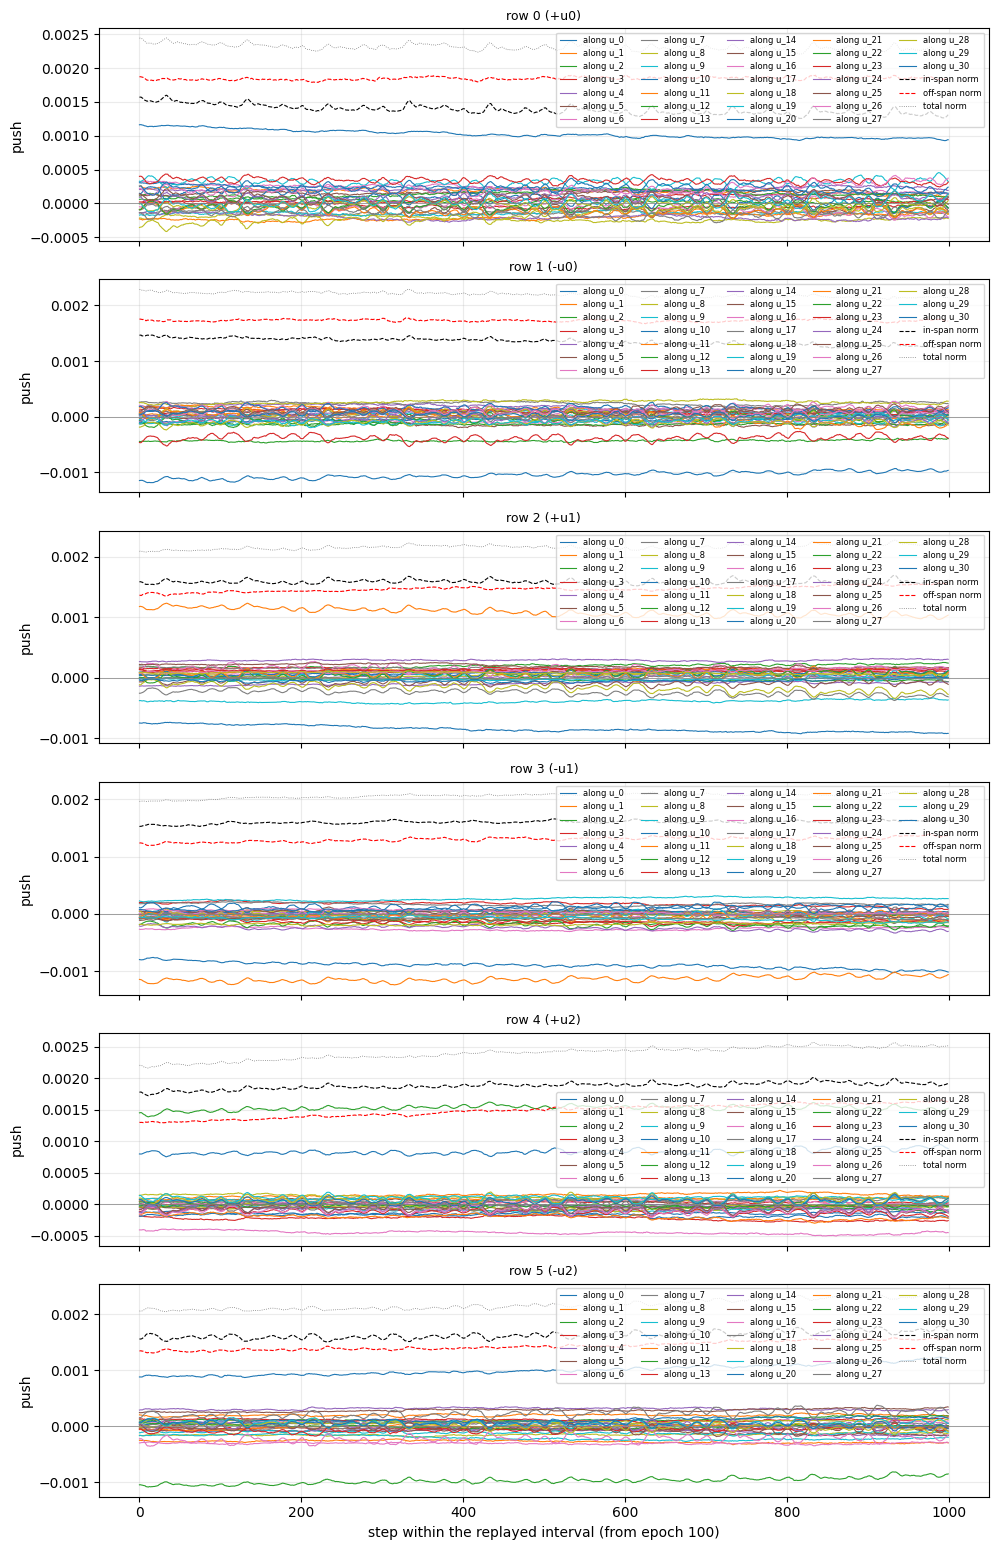

row 0: mean per-step |push| 0.0023, |mean push| 0.0023, mean push along its target +0.0010, actual displacement over the interval along target +0.0998
row 1: mean per-step |push| 0.0022, |mean push| 0.0022, mean push along its target +0.0010, actual displacement over the interval along target +0.1044
row 2: mean per-step |push| 0.0022, |mean push| 0.0021, mean push along its target +0.0011, actual displacement over the interval along target +0.1025
row 3: mean per-step |push| 0.0021, |mean push| 0.0020, mean push along its target +0.0011, actual displacement over the interval along target +0.1251
row 4: mean per-step |push| 0.0024, |mean push| 0.0024, mean push along its target +0.0015, actual displacement over the interval along target +0.1285
row 5: mean per-step |push| 0.0022, |mean push| 0.0022, mean push along its target +0.0010, actual displacement over the interval along target +0.1056


In [19]:
NODE_IDS = list(range(31))  # all nodes in the hierarchy
PUSH, NORMALIZE = True, False
grads_by_step = {int(s): rep["full_grad_rows"][i] for i, s in enumerate(rep["step"])}
# the series tool expects full first-layer gradients; embed the recorded rows into a zero matrix of the right width
n_rows, dim = W["hidden_layers.0.weight"].shape[1:]
full = {s: np.zeros((n_rows, dim)) for s in grads_by_step}
for s, g in grads_by_step.items():
    full[s][ROWS] = g
gser = first_layer_gradient_series(full, tree, neuron_ids=ROWS, node_ids=NODE_IDS, push=PUSH, normalize=NORMALIZE).rename(columns={"epoch": "step"})
fig, axes = plt.subplots(len(ROWS), 1, figsize=(10, 2.6 * len(ROWS)), sharex=True, squeeze=False); axes = axes[:, 0]
for ax, r in zip(axes, ROWS):
    g = gser[gser.neuron == r]
    for k, n in enumerate(NODE_IDS): ax.plot(g.step, g[f"comp_{n}"], lw=0.8, label=f"along u_{n}")
    ax.plot(g.step, g.inspan_norm, color="k", lw=0.8, ls="--", label="in-span norm");
    ax.plot(g.step, g.offspan_norm, color="r", lw=0.8, ls="--", label="off-span norm"); 
    ax.plot(g.step, g.grad_norm, color="gray", lw=0.6, ls=":", label="total norm")
    ax.axhline(0, color="gray", lw=0.5); ax.set_ylabel(("cos " if NORMALIZE else "") + ("push" if PUSH else "grad")); ax.set_title(f"row {r} ({'+' if HIERARCHY_TARGETS[r][1] > 0 else '-'}u{HIERARCHY_TARGETS[r][0]})", fontsize=9); ax.grid(alpha=0.25); ax.legend(fontsize=6, ncol=5)
axes[-1].set_xlabel(f"step within the replayed interval (from epoch {EPOCH_START})"); fig.tight_layout(); plt.show()
# running mean of the push vs the per-step push: what the row actually integrates
for r in ROWS:
    g = gser[gser.neuron == r]; mean_push = -rep["full_grad_rows"][:, ROWS.index(r)].mean(0); U0 = tree.w_list[HIERARCHY_TARGETS[r][0]] / np.linalg.norm(tree.w_list[HIERARCHY_TARGETS[r][0]])
    print(f"row {r}: mean per-step |push| {g.grad_norm.mean():.4f}, |mean push| {np.linalg.norm(mean_push):.4f}, mean push along its target {HIERARCHY_TARGETS[r][1] * (mean_push @ U0):+.4f}, actual displacement over the interval along target {HIERARCHY_TARGETS[r][1] * ((rep['params_rows'][-1, ROWS.index(r)] - rep['params_rows'][0, ROWS.index(r)]) @ U0):+.4f}")


## 4. Mini-batch step vs population gradient, and the batch loss, within the interval

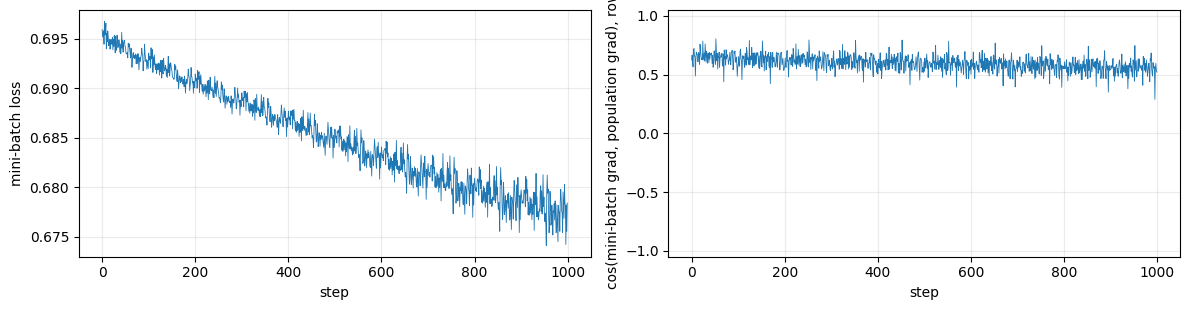

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(rep["step"], rep["batch_loss"], lw=0.6); axes[0].set_ylabel("mini-batch loss"); axes[0].set_xlabel("step")
cosines = [float((-rep["grad_rows"][i, 0] @ -rep["full_grad_rows"][i, 0]) / (np.linalg.norm(rep["grad_rows"][i, 0]) * np.linalg.norm(rep["full_grad_rows"][i, 0]) + 1e-30)) for i in range(rep["num_steps"])]
axes[1].plot(rep["step"], cosines, lw=0.6); axes[1].set_ylabel(f"cos(mini-batch grad, population grad), row {ROWS[0]}"); axes[1].set_xlabel("step"); axes[1].set_ylim(-1.05, 1.05)
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout(); plt.show()


## 5. Network graph at a checkpoint

Visible edges: 47 / 3640
First-layer aligned nodes: 38 / 80


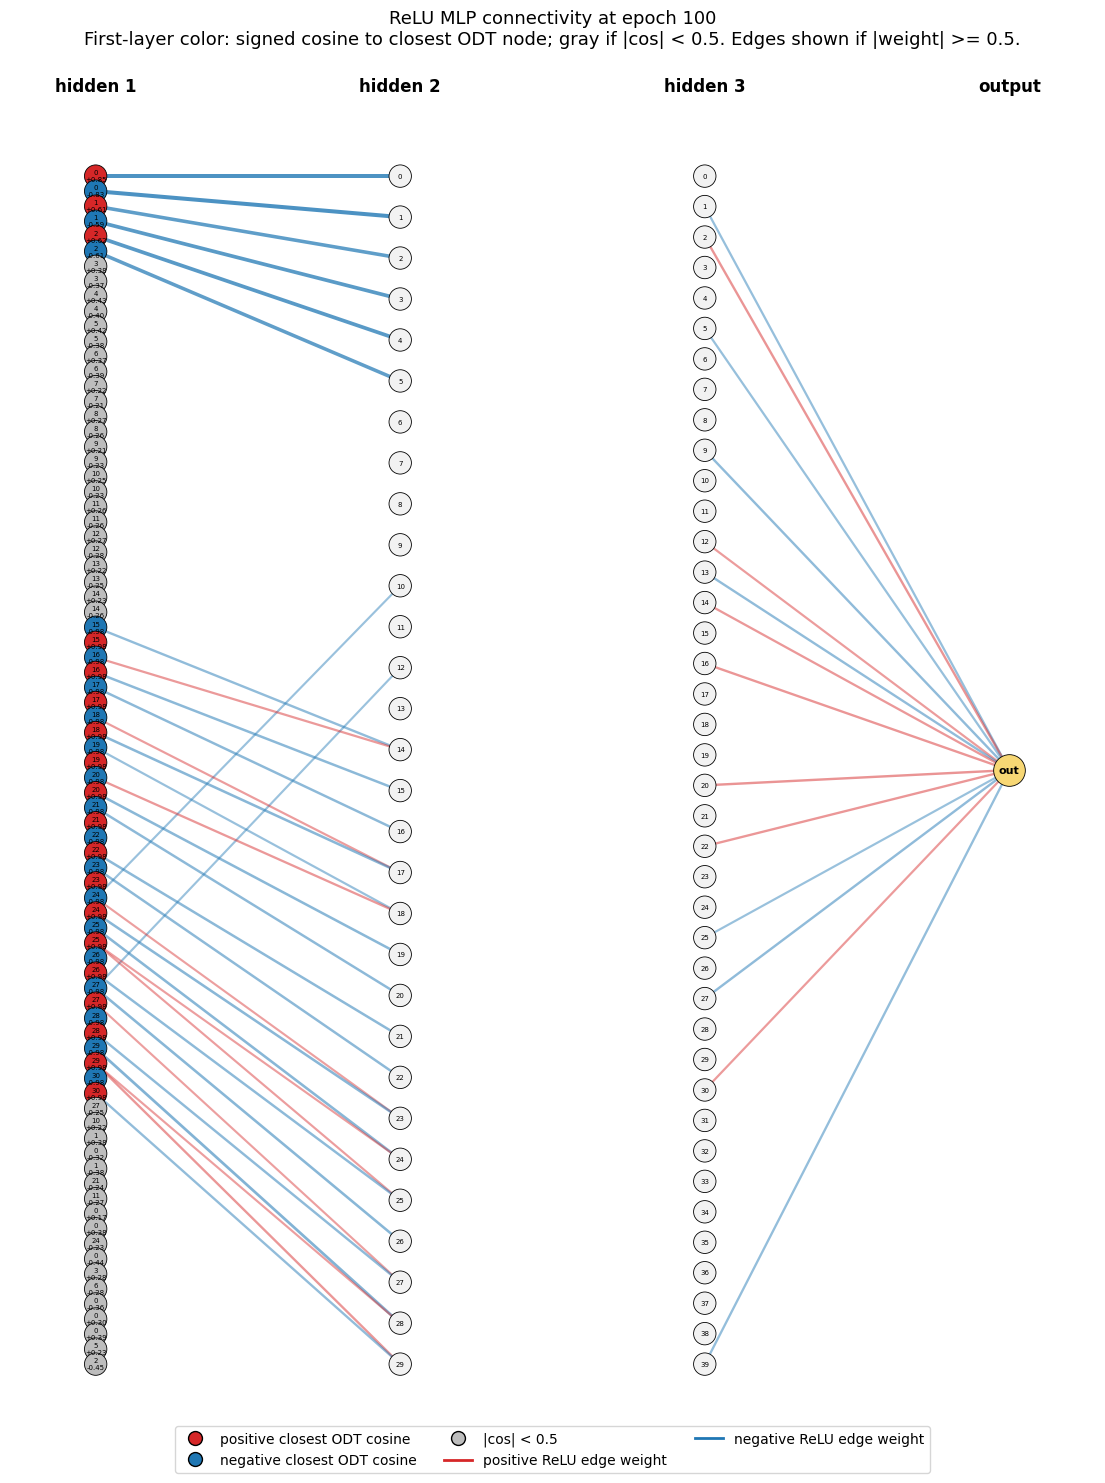

In [6]:
GRAPH_EPOCH = 100
sd = snapshot_state_dict(run, GRAPH_EPOCH); al = first_layer_odt_alignment(state_dict=sd, tree=tree)
mask = [al["max_abs_cos"].numpy() >= 0.5] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]
_ = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=GRAPH_EPOCH, node_mask=mask, alignment_abs_threshold=0.5, edge_abs_threshold=0.5, figsize=(14, 18)); plt.show()
